# Can a computer predict BatChat's favorite Batman stories?

*Undone* ranks **47th** of the 740 Batman stories on BatChat. The models place it hundreds of ranks lower. The metadata models know who made the comic and when it came out, but they never see Bruce holding Damian’s costume and crying.

How much of BatChat's taste can a model learn from creators, dates, characters, and plot summaries?

**Rank 1 is best.** New to the data? Start with [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) or [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree).

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)*

In [1]:
from itertools import pairwise
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
pd.set_option("display.max_rows", 20)
pd.set_option("display.min_rows", 10)
pd.set_option("styler.render.max_rows", 20)

sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
texts = pd.read_csv(DATA / "story_texts.csv")
N = len(stories)
y = stories["rank"].to_numpy(dtype=float)
print(f"{N} ranked stories, from {stories.title[0]} (#1) to {stories.title[N - 1]} (#{N})")

740 ranked stories, from Year One (#1) to Batman: Three Jokers #1-3 (#740)


## Inputs

Publication year, issue count, discussion timing, format, selected-story credits, featured characters, antagonists, and creators' pre-publication Eisner wins. Names become presence indicators; missing metadata remains unknown. Names and text terms need eight training stories; rarer format categories share a pooled indicator. The threshold is learned within each training fold. It reduces rare-feature noise, but does not separate a creator from their usual era or run.

Three example rows show the inputs below. `New Earth` and `Prime Earth` are continuity labels.

In [2]:
MIN_STORIES = 8
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = ["narrative_" + role for role in ROLES]
CAST = ["featured_entity_ids", "antagonists_entity_ids"]
WHEN = ["cover_year_start", "issue_count", "discussion_day"]
AWARDS = ["creator_eisner_personal_wins_pre_publication"]
TFIDF = dict(stop_words="english", min_df=MIN_STORIES, max_df=0.9, sublinear_tf=True)

X = stories[
    ["medium", "format_hint", "cover_year_start", "issue_count", *NAMES, *CAST, *AWARDS]
].copy()
dates = pd.to_datetime(stories.discussion_date)
X["discussion_day"] = (dates - dates.min()).dt.days
X[NAMES + CAST] = X[NAMES + CAST].fillna("")


def model(numbers=(), name_lists=(), text=None, forest=False):
    """Numbers are scaled, format is one-hot encoded, every name in a list becomes a 0/1 column,
    and `text` (a column name) becomes TF-IDF word weights."""
    features = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(numbers)),
        (
            OneHotEncoder(handle_unknown="ignore", min_frequency=MIN_STORIES),
            ["medium", "format_hint"],
        ),
        *[
            (
                CountVectorizer(
                    token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=MIN_STORIES
                ),
                col,
            )
            for col in name_lists
        ],
        *([(TfidfVectorizer(**TFIDF), text)] if text else []),
    )
    if forest:
        return make_pipeline(
            features,
            RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
        )
    return make_pipeline(features, RidgeCV(alphas=np.logspace(-1, 3, 9)))


X.head(3).T

,0,1,2
medium,comic,comic,comic
format_hint,unspecified,unspecified,unspecified
cover_year_start,1987.0,2000.0,2018.0
issue_count,4.0,1.0,3.0
narrative_writers,Frank Miller,Darwyn Cooke,Tom King
narrative_pencilers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_inkers,Dave Mazzucchelli,Darwyn Cooke,Lee Weeks
narrative_colorists,Richmond Lewis,Darwyn Cooke,Elizabeth Breitweiser
narrative_letterers,Todd Klein,Jon Babcock,Clayton Cowles
narrative_editors,Dennis O'Neil,Mark Chiarello,Brittany Holzherr|Jamie S. Rich


## Can we beat guessing the middle?

Compare ridge regression and a random forest with a training-fold average baseline. Error is measured in rank places: a prediction of #200 for the story at #100 misses by 100.

<details><summary>Validation</summary>

Every prediction is held out. Five folds keep stories sharing an issue or episode together, preventing related readings from appearing on both sides of a split. Preprocessing is fitted within each training fold. These are retrospective splits, not forecasts of future episodes: creators and eras can still occur in several folds. Rank gaps measure positions on this list, not equal gaps in enjoyment.

</details>

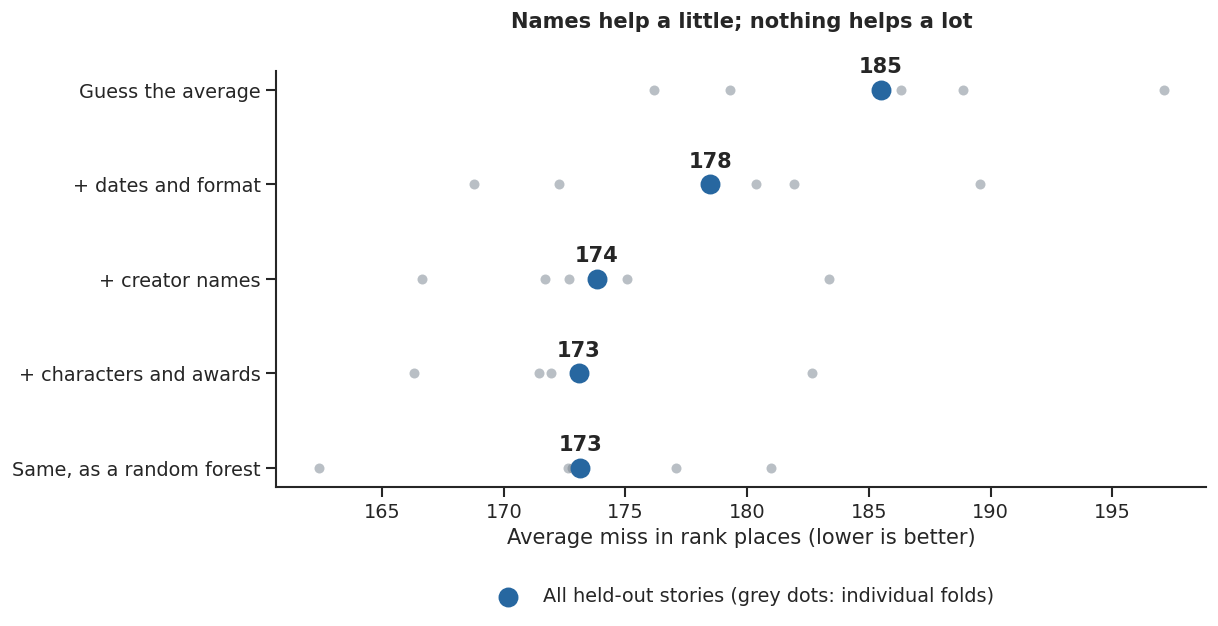

In [3]:
# Stories that share an issue or an episode stay in the same fold.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

ladder = {
    "Guess the average": DummyRegressor(),
    "+ dates and format": model(WHEN),
    "+ creator names": model(WHEN, NAMES),
    "+ characters and awards": model(WHEN + AWARDS, NAMES + CAST),
    "Same, as a random forest": model(WHEN + AWARDS, NAMES + CAST, forest=True),
}
predictions = {name: cross_val_predict(m, X, y, cv=folds) for name, m in ladder.items()}
fold_errors = pd.DataFrame(
    {
        name: [mean_absolute_error(y[test], p[test]) for _, test in folds]
        for name, p in predictions.items()
    }
).melt(var_name="model", value_name="error")
errors = pd.Series({name: mean_absolute_error(y, p) for name, p in predictions.items()})

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(
    data=fold_errors, x="error", y="model", color=GREY, alpha=0.5, size=6, jitter=False, ax=ax
)
ax.scatter(
    errors,
    range(len(errors)),
    color=BLUE,
    s=120,
    zorder=3,
    label="All held-out stories (grey dots: individual folds)",
)
for pos, value in enumerate(errors):
    ax.annotate(
        f"{value:.0f}",
        (value, pos),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontweight="bold",
    )
ax.set(
    xlabel="Average miss in rank places (lower is better)",
    ylabel="",
    title="Names help a little; nothing helps a lot\n",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()

The models improve modestly on the baseline, but still miss by about **170 rank places**. Fold-to-fold variation is large relative to the smaller gains between feature sets.

Below: actual rank across, held-out prediction up. Each dot is one story.

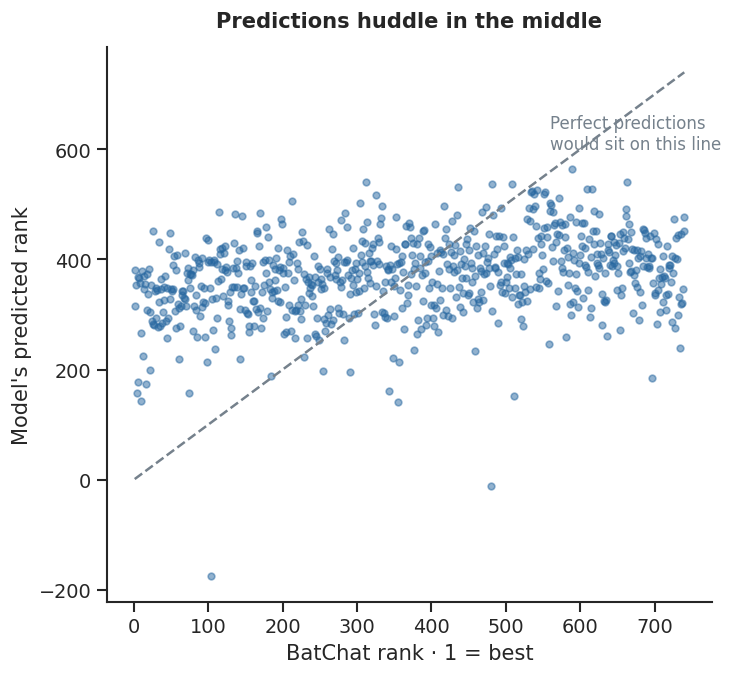

In [4]:
best = "+ characters and awards"
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y, predictions[best], s=16, alpha=0.5, color=BLUE)
ax.plot([1, N], [1, N], ls="--", color=GREY)
ax.annotate("Perfect predictions\nwould sit on this line", (560, 600), color=GREY, fontsize=10)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="Model's predicted rank",
    title="Predictions huddle in the middle",
)
plt.show()

Predictions mostly pull the extremes toward the middle. Ridge regression can also predict outside #1–#740; those are unconstrained scores, not valid list positions. Shared creators and dates leave plenty of room for different reading experiences.

## What about an unseen artist?

For each of the five busiest pencilers, remove all their stories from training and predict them together.

In [5]:
rows = []
names = X[NAMES].apply(lambda col: col.str.split("|").map(set))
artists = names.narrative_pencilers.explode().value_counts().head(5).index
for artist in artists:
    involved = names.apply(lambda col: col.map(lambda s: artist in s)).any(axis=1)
    test = names.narrative_pencilers.map(lambda s: artist in s).to_numpy()
    train = (~involved & ~pd.Series(groups).isin(groups[test])).to_numpy()
    fitted = ladder[best].fit(X[train], y[train])
    rows.append(
        {
            "Artist": artist,
            "Stories": test.sum(),
            "Their median rank": np.median(y[test]),
            "Model's miss (rank places)": mean_absolute_error(y[test], fitted.predict(X[test])),
            "Average-guess miss (rank places)": mean_absolute_error(
                y[test], np.full(test.sum(), y[train].mean())
            ),
        }
    )
pd.DataFrame(rows).set_index("Artist").round(0)

,Stories,Their median rank,Model's miss (rank places),Average-guess miss (rank places)
Artist,,,,
Jim Aparo,24,364.0,152.0,169.0
Bob Kane,20,544.0,137.0,190.0
Norm Breyfogle,19,324.0,133.0,140.0
Kelley Jones,16,312.0,225.0,212.0
Neal Adams,16,398.0,156.0,173.0


For withheld Kelley Jones stories, the model does worse than guessing the training average. His books span *Red Rain* (#6) to *Unseen* (#716), both written by Doug Moench. Knowing the surrounding credits is no guarantee of knowing the hosts’ response.

## The interesting misses

These are the largest ridge errors where the forest agrees on the direction of the miss; the forest need not be equally far off. These are starting points for a reading comparison; the [reranking notebook](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) examines twenty cases.

In [6]:
misses = stories[["title", "rank"]].assign(
    ridge=predictions[best].round(), forest=predictions["Same, as a random forest"].round()
)
misses["surprise"] = misses.ridge - misses["rank"]
both_agree = np.sign(misses.surprise) == np.sign(misses.forest - misses["rank"])
columns = {
    "title": "Story",
    "rank": "BatChat rank",
    "ridge": "Model guessed",
    "forest": "Forest guessed",
}
for caption, pick in [
    (
        "The hosts ranked these much higher than the metadata models predicted:",
        misses[both_agree].nlargest,
    ),
    ("…and these much lower:", misses[both_agree].nsmallest),
]:
    print(caption)
    display(pick(8, "surprise")[list(columns)].rename(columns=columns).set_index("Story"))

The hosts ranked these much higher than the metadata models predicted:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Final Crisis,26,452.0,438.0
Night of the Stalker,48,448.0,462.0
The Dark Knight Returns: The Last Crusade,33,431.0,394.0
Ego,2,381.0,407.0
Undone,47,419.0,490.0
The Joker/ The Joker Returns,114,485.0,524.0
The Joker’s Five-Way Revenge,11,380.0,414.0
Batman/Dracula: Red Rain OGN,6,369.0,314.0


…and these much lower:


,BatChat rank,Model guessed,Forest guessed
Story,,,
Knightquest: The Search,697,185.0,307.0
Batman: White Knight #1-8,734,240.0,283.0
Batman & Robin Eternal #1-26,480,-12.0,257.0
Batman/Green Arrow: The Poison Tomorrow,727,276.0,287.0
Batman Vs. the Undead,724,286.0,327.0
Superman and Batman Vs. Vampires and Werewolves,732,298.0,292.0
The Wedding,703,283.0,370.0
Odyssey,735,318.0,380.0


*White Knight* (#734), *Unseen*, and *Knightquest: The Search* sit well below their predictions. Familiar credits do not explain the hosts' response to each book.

## Does the plot help?

The wiki summaries contain roughly **700,000 words**. TF-IDF weights recurring, distinctive terms, but discards word order and images. About a fifth of stories have no usable summary, with recent comics especially underrepresented.

In [7]:
available = texts[texts.text_status.eq("available")].drop_duplicates(["story_id", "synopsis_text"])
X["plot_text"] = stories.story_id.map(
    available.groupby("story_id").synopsis_text.agg(" ".join)
).fillna("")
X["has_plot"] = X.plot_text.ne("").astype(float)
plot_ladder = {
    "Plot words and format": model(text="plot_text"),
    "Names, dates, cast and awards": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST),
    "… plus plot words": model(WHEN + AWARDS + ["has_plot"], NAMES + CAST, text="plot_text"),
}
plot_scores = pd.Series(
    {"Guess the average": errors["Guess the average"]}
    | {
        name: mean_absolute_error(y, cross_val_predict(m, X, y, cv=folds))
        for name, m in plot_ladder.items()
    },
    name="Average miss (rank places)",
)
plot_scores.round(1).to_frame()

,Average miss (rank places)
Guess the average,185.5
Plot words and format,182.1
"Names, dates, cast and awards",173.0
… plus plot words,173.0


Plot words with format narrowly beat the average-rank baseline. Adding words to the richer metadata model brings little further improvement. Both richer models include a flag for summary availability, so their comparison isolates the words from simply having a summary.

## Better for finding related stories?

For *Undone*, *Ego*, and *The Clown at Midnight*, find the story with the closest word profile. Candidates need at least 200 summary words; stories sharing an episode or issue are excluded. This is descriptive similarity fitted on the available corpus, not another held-out prediction test. Blue is the query, orange its match; the words on the right contribute most to their similarity.

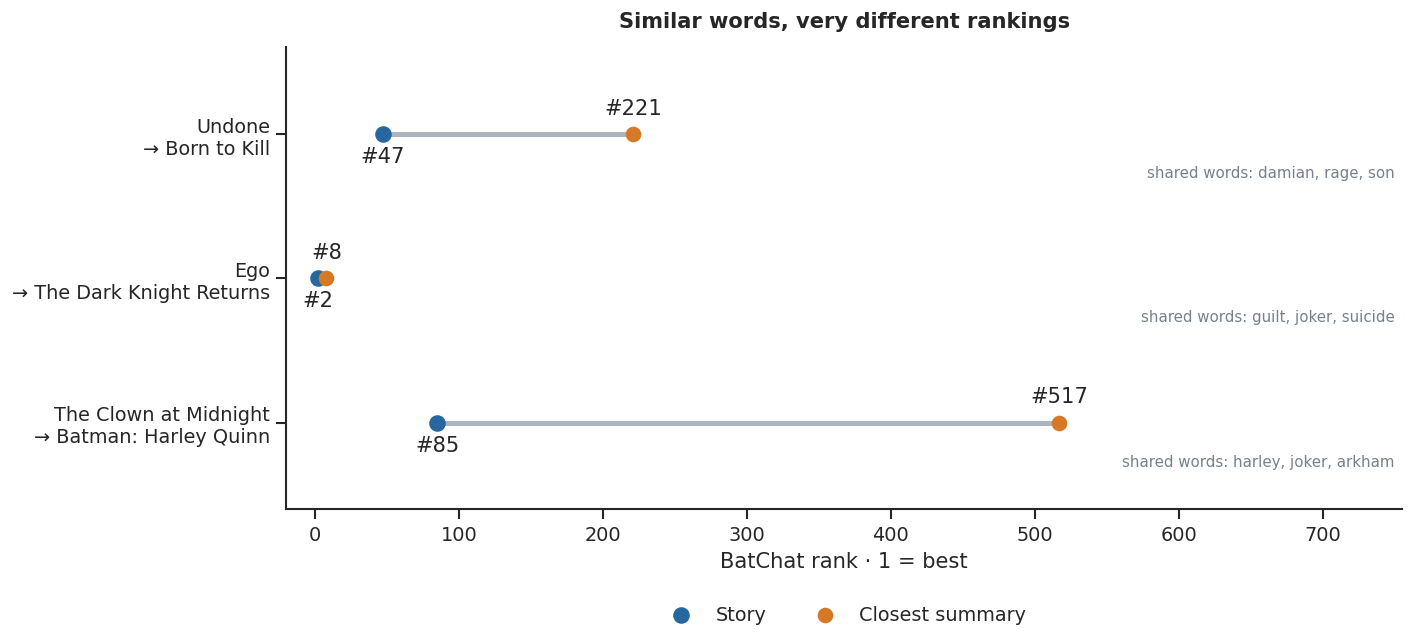

In [8]:
has_text = np.flatnonzero(X.plot_text.str.split().str.len().ge(200))
words = TfidfVectorizer(**TFIDF)
vectors = words.fit_transform(X.plot_text.iloc[has_text])
similarity = cosine_similarity(vectors)
pairs = []
for title in ["Undone", "Ego", "The Clown at Midnight"]:
    i = int(np.flatnonzero(stories.title.iloc[has_text].eq(title))[0])
    scores = np.where(groups[has_text] == groups[has_text[i]], -1, similarity[i])
    j = int(scores.argmax())
    shared = vectors[i].multiply(vectors[j]).toarray().ravel()
    pairs.append(
        {
            "story": title,
            "story_rank": int(y[has_text[i]]),
            "closest": stories.title.iloc[has_text[j]],
            "closest_rank": int(y[has_text[j]]),
            "shared_words": ", ".join(words.get_feature_names_out()[np.argsort(-shared)[:3]]),
        }
    )
pairs = pd.DataFrame(pairs)

fig, ax = plt.subplots(figsize=(12, 5))
for pos, row in pairs.iterrows():
    ax.plot([row.story_rank, row.closest_rank], [pos, pos], color="#ABB5BD", lw=3, zorder=1)
    ax.annotate(
        f"#{row.story_rank}",
        (row.story_rank, pos),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center",
    )
    ax.annotate(
        f"#{row.closest_rank}",
        (row.closest_rank, pos),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
    )
    ax.text(
        N + 10, pos + 0.3, f"shared words: {row.shared_words}", ha="right", fontsize=9, color=GREY
    )
ax.scatter(pairs.story_rank, pairs.index, color=BLUE, s=80, zorder=3, label="Story")
ax.scatter(pairs.closest_rank, pairs.index, color=ORANGE, s=70, zorder=3, label="Closest summary")
ax.set(
    yticks=pairs.index,
    yticklabels=[fill(r.story, 25) + "\n→ " + fill(r.closest, 25) for r in pairs.itertuples()],
    xlim=(-20, N + 15),
    ylim=(len(pairs) - 0.4, -0.6),
    xlabel="BatChat rank · 1 = best",
    title="Similar words, very different rankings",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.show()

*Undone* and *Born to Kill* share **Damian, rage, and son**, despite ranking #47 and #221. **Guilt, Joker, and suicide** link *Ego* (#2) with *The Dark Knight Returns* (#8).

The third pair makes the limitation vivid: *The Clown at Midnight* (#85) and *Batman: Harley Quinn* (#517) share **Harley, Joker, and Arkham**, but sit 432 places apart. Shared vocabulary can suggest a reading comparison without implying equal quality.

Names and dates offer modest predictive value; summaries suggest comparisons. Large residuals are unexplained by these models, not evidence that the hosts ranked a story incorrectly.

Read next: [Twenty reranking cases](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) · [Feature effects and support](https://www.kaggle.com/code/danofer/what-pushes-a-batman-story-up-batchat-s-list)